# 🌡️ Previsão da temperatura média mensal no Rio de Janeiro com XGBoost

Projeto de **machine learning para séries temporais**: prever a temperatura média do **mês seguinte** a partir de informações do mês atual.

## Pergunta
> É possível prever a temperatura média do próximo mês no Rio de Janeiro e quão melhor é um modelo de machine learning do que referências simples?

## Roteiro
1. Carregar e explorar os dados
2. Separar treino e teste (respeitando a ordem do tempo)
3. Treinar o XGBoost e avaliar
4. Comparar com modelos simples de referência
5. Entender o que o modelo aprendeu (importância das variáveis e erros)
6. Validar a robustez com validação cruzada temporal
7. Conclusões e limitações

> **Crédito e origem dos dados:** veja o README do repositório.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import r2_score, mean_absolute_percentage_error
from xgboost import XGBRegressor
from pathlib import Path

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

sns.set_theme(style="whitegrid")
IMG = Path("images")
IMG.mkdir(exist_ok=True)

In [2]:
# pip install pandas numpy seaborn matplotlib scikit-learn xgboost

## 1. Carregamento e preparação dos dados

In [3]:
# Importar base de dados pré-processados
# Ler arquivo CSV e converter para DataFrame (tabelas em python)

df = pd.read_csv(
    r"dados/dados_preprocessados_temp_rj.csv",
    index_col = "time",
    parse_dates = True
)
df


,TAMB,seno_mes,cos_mes,media_movel_3m,media_movel_12m,std_movel_3m,std_movel_12m,TARGET
time,,,,,,,,
1991-12-01,26.519355,-2.449294e-16,1.000000e+00,24.443082,23.412252,1.866790,2.128632,25.835484
1992-01-01,25.835484,5.000000e-01,8.660254e-01,25.420502,23.476499,1.354877,2.193676,26.065517
1992-02-01,26.065517,8.660254e-01,5.000000e-01,26.140119,23.488506,0.347985,2.208618,26.029032
1992-03-01,26.029032,1.000000e+00,6.123234e-17,25.976678,23.530173,0.123631,2.254846,25.043333
1992-04-01,25.043333,8.660254e-01,-5.000000e-01,25.712628,23.583506,0.579913,2.284747,23.738710
...,...,...,...,...,...,...,...,...
2025-05-01,22.619355,5.000000e-01,-8.660254e-01,24.520179,24.187899,1.922950,2.190660,21.296667
2025-06-01,21.296667,1.224647e-16,-1.000000e+00,22.797563,24.065954,1.597473,2.314594,19.716129
2025-07-01,19.716129,-5.000000e-01,-8.660254e-01,21.210717,23.964610,1.453520,2.484653,20.909677


### Entendendo as colunas

| Coluna | Descrição |
|---|---|
| `TAMB` | Temperatura média do mês atual (°C) |
| `seno_mes`, `cos_mes` | Mês do ano codificado de forma cíclica (para o modelo saber que dezembro e janeiro são vizinhos) |
| `media_movel_3m`, `media_movel_12m` | Média da temperatura nos últimos 3 e 12 meses |
| `std_movel_3m`, `std_movel_12m` | Desvio padrão da temperatura nos últimos 3 e 12 meses |
| `TARGET` | **Temperatura média do mês seguinte (°C)**, a variável que queremos prever |

As janelas móveis usam apenas dados até o mês atual, então não há vazamento de informação do futuro.

In [4]:
# Conferindo: o TARGET de cada mês é a temperatura (TAMB) do mês seguinte?
print("TARGET é a TAMB do mês seguinte:", np.allclose(df["TARGET"].iloc[:-1].values, df["TAMB"].iloc[1:].values))
print("Período das features:", df.index.min().strftime("%m/%Y"), "a", df.index.max().strftime("%m/%Y"))
print("Valores nulos:", int(df.isna().sum().sum()))

TARGET é a TAMB do mês seguinte: True
Período das features: 12/1991 a 09/2025
Valores nulos: 0


## 2. Exploração inicial dos dados

,TARGET
count,406.000000
mean,23.791794
std,2.241930
min,19.277419
25%,21.901613
50%,23.811505
75%,25.769605
max,28.864286


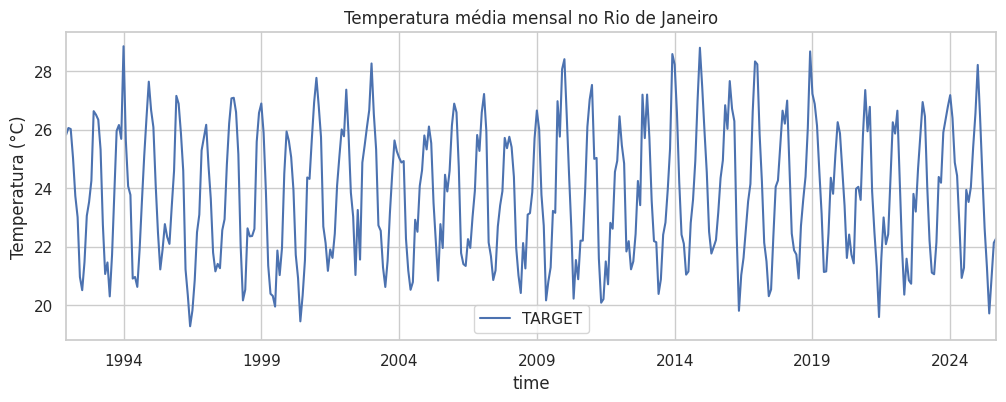

In [5]:
# Breve análise descritiva com estatísticas básicas dos dados
display(df[["TARGET"]].describe())

# Visualizar dados de forma visual (gráfico de linha)
ax = df[["TARGET"]].plot(figsize=(12, 4), title="Temperatura média mensal no Rio de Janeiro")
ax.set_ylabel("Temperatura (°C)")
plt.savefig(IMG / "01_serie_temperatura.png", dpi=150, bbox_inches="tight")

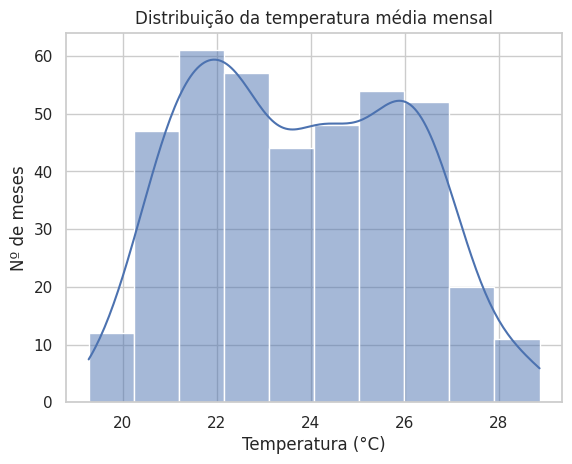

In [6]:
# Visualizar distribuição dos dados (gráfico de histograma)
sns.histplot(df[["TARGET"]], kde=True, legend=False)
plt.title("Distribuição da temperatura média mensal")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Nº de meses")
plt.savefig(IMG / "02_distribuicao_temperatura.png", dpi=150, bbox_inches="tight")

**Leitura:** a temperatura média mensal varia entre cerca de 19 °C e 29 °C, com média em torno de 23,8 °C. A série tem um padrão sazonal muito claro, com verões quentes e invernos mais amenos, repetido todos os anos.

## 3. Preparação para o treinamento

In [7]:
# Criando uma cópia dos dados originais
df_preprocessado = df.copy()

In [8]:
df_preprocessado.head(5)

,TAMB,seno_mes,cos_mes,media_movel_3m,media_movel_12m,std_movel_3m,std_movel_12m,TARGET
time,,,,,,,,
1991-12-01,26.519355,-2.449294e-16,1.000000e+00,24.443082,23.412252,1.866790,2.128632,25.835484
1992-01-01,25.835484,5.000000e-01,8.660254e-01,25.420502,23.476499,1.354877,2.193676,26.065517
1992-02-01,26.065517,8.660254e-01,5.000000e-01,26.140119,23.488506,0.347985,2.208618,26.029032
1992-03-01,26.029032,1.000000e+00,6.123234e-17,25.976678,23.530173,0.123631,2.254846,25.043333
1992-04-01,25.043333,8.660254e-01,-5.000000e-01,25.712628,23.583506,0.579913,2.284747,23.738710


In [9]:
# Separação dos dados em TARGET (y) e FEATURES (x)


# Target = Variável Prevista = Y 
y_target = df_preprocessado[["TARGET"]]

# Features = Variável(is) Preditora(s) = X
# Neste caso, temos a informações do mês atual (a temperatura prevista é a do mês seguinte)
x_features = df_preprocessado.drop(columns="TARGET")

In [10]:
# Separação em treino e teste
# Seguiremos uma separação padrão de ~70% para treino e 30% para teste

# Primeiros 25 anos destinados para treinamento (1991 - 2015)
y_train = y_target["1991": "2015"]
x_train = x_features["1991": "2015"]

# Últimos 10 anos destinados para teste/validação (2016 - 2025)
y_test = y_target["2016":]
x_test = x_features["2016":]

# Visualizando percentuais das amostras
pct_treino = (len(y_train) / len(y_target)) * 100
print(f"Percentual de dados para treinamento: {pct_treino:.0f}%")

pct_teste = (len(y_test) / len(y_target)) *100
print(f"Percentual de dados para teste: {pct_teste:.0f}%")

Percentual de dados para treinamento: 71%
Percentual de dados para teste: 29%


A separação respeita a **ordem do tempo**: treino com os primeiros 25 anos e teste com os últimos 10. Em séries temporais, embaralhar os dados vazaria informação do futuro para o treino.

## 4. Treinamento do modelo

In [11]:
# Modelo escolhido -> XGBoost -> Modelo de gradiente
# Bastante utilizado em séries temporais

modelo = XGBRegressor() # modelo com configuração padrão

 # Modelo parametrizado
modelo = XGBRegressor(
    random_state=42,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    colsample_bytree=0.8,
    subsample=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
)

# Treinar modelo com dados de treinamento
modelo.fit(x_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [12]:
# Buscar previsões nas amostras de treino e teste para validação
pred_train = pd.DataFrame(modelo.predict(x_train), index=x_train.index, columns=["Y_PRED"])
pred_test = pd.DataFrame(modelo.predict(x_test), index=x_test.index, columns=["Y_PRED"])

# Visualizar previsões
pred_test

,Y_PRED
time,
2016-01-01,26.989929
2016-02-01,26.006008
2016-03-01,25.448868
2016-04-01,22.829737
2016-05-01,21.670950
...,...
2025-05-01,20.903221
2025-06-01,21.036745
2025-07-01,21.078676


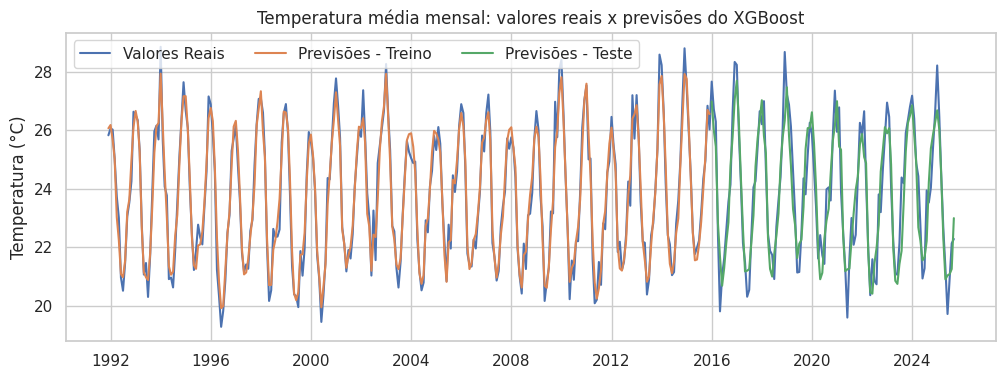

In [13]:
# Plotar previsões vs. dados reais

# Criando figura
fig, ax = plt.subplots(figsize=(12, 4))

# Plotando dados
ax.plot(y_target, label="Valores Reais")
ax.plot(pred_train, label="Previsões - Treino")
ax.plot(pred_test, label="Previsões - Teste")

ax.legend(ncols=3)
ax.set_title("Temperatura média mensal: valores reais x previsões do XGBoost")
ax.set_ylabel("Temperatura (°C)")
plt.savefig(IMG / "03_previsoes_vs_reais.png", dpi=150, bbox_inches="tight")

## 5. Avaliação do modelo

In [14]:
# R2 -> coeficiente de determinação
# -> mostra quanto da variância total dos seus dados seu modelo consegue explicar
# -> mostra quão bem seu modelo explica o comportamento da sua série
# -> quanto maior melhor

r2_test = r2_score(y_true=y_test, y_pred=pred_test)
r2_train = r2_score(y_true=y_train, y_pred=pred_train)

print(f"Valores de R² -> Treino: {r2_train:.2f} | Teste: {r2_test:.2f}")

# MAPE -> erro médio absoluto percentual percentual
# -> medida de erro global do seu modelo
# -> quanto menor melhor

mape_test = mean_absolute_percentage_error(y_true=y_test, y_pred=pred_test) * 100
mape_train = mean_absolute_percentage_error(y_true=y_train, y_pred=pred_train) * 100

print(f"Valores de MAPE -> Treino: {mape_train:.2f}% | Teste: {mape_test:.2f}%")

Valores de R² -> Treino: 0.96 | Teste: 0.85
Valores de MAPE -> Treino: 1.45% | Teste: 3.03%


In [15]:
# Erro em graus Celsius, mais fácil de interpretar do que o percentual
mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = mean_squared_error(y_test, pred_test) ** 0.5
print(f"Teste -> MAE: {mae_test:.2f} °C | RMSE: {rmse_test:.2f} °C")

Teste -> MAE: 0.72 °C | RMSE: 0.88 °C


**Leitura:** o R² cai de ~0,96 no treino para ~0,85 no teste, um sinal de que o modelo se ajusta um pouco melhor aos dados que já viu do que aos novos (**sobreajuste moderado**). No teste, o erro médio é de cerca de **0,7 °C**.

Mas "bom" em relação a quê? Um R² de 0,85 só significa algo quando comparado a referências simples. É o que fazemos a seguir.

## 6. Comparação com modelos simples de referência (baselines)

In [16]:
# Previsões de referência para o mesmo período de teste
resultados = {}
resultados["XGBoost"] = pred_test["Y_PRED"]

# 1) Persistência: "o mês que vem será igual a este mês"
resultados["Persistência (mês atual)"] = x_test["TAMB"]

# 2) Sazonal ingênuo: "o mês que vem será igual ao mesmo mês do ano anterior"
resultados["Sazonal ingênuo (ano anterior)"] = x_features["TAMB"].shift(11).loc["2016":]

# 3) Climatologia: média histórica do mês-alvo, calculada só com dados de treino
alvo_treino = y_train.copy()
alvo_treino["mes_alvo"] = alvo_treino.index.month % 12 + 1
clima = alvo_treino.groupby("mes_alvo")["TARGET"].mean()
mes_alvo_teste = y_test.index.month % 12 + 1
resultados["Climatologia (média por mês)"] = pd.Series(clima.reindex(mes_alvo_teste).values, index=y_test.index)

# 4) Regressão linear com as mesmas features
reg = LinearRegression().fit(x_train, y_train)
resultados["Regressão linear"] = pd.Series(reg.predict(x_test).ravel(), index=y_test.index)

linhas = []
for nome, previsao in resultados.items():
    p = pd.Series(previsao).reindex(y_test.index)
    linhas.append({
        "Modelo": nome,
        "R²": r2_score(y_test["TARGET"], p),
        "MAE (°C)": mean_absolute_error(y_test["TARGET"], p),
        "RMSE (°C)": mean_squared_error(y_test["TARGET"], p) ** 0.5,
        "MAPE (%)": mean_absolute_percentage_error(y_test["TARGET"], p) * 100,
    })

comparacao = pd.DataFrame(linhas).set_index("Modelo").round(2).sort_values("MAE (°C)")
comparacao

,R²,MAE (°C),RMSE (°C),MAPE (%)
Modelo,,,,
Climatologia (média por mês),0.84,0.70,0.90,2.92
Regressão linear,0.85,0.71,0.86,2.98
XGBoost,0.85,0.72,0.88,3.03
Sazonal ingênuo (ano anterior),0.70,0.99,1.24,4.17
Persistência (mês atual),0.57,1.26,1.47,5.31


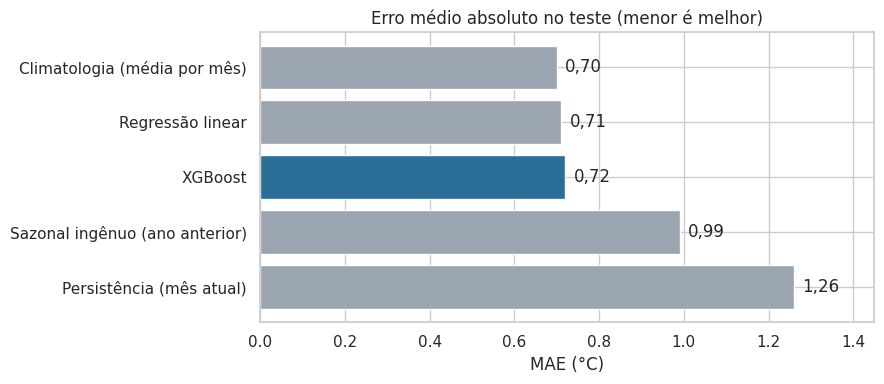

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
ordem = comparacao["MAE (°C)"].sort_values(ascending=False)
cores = ["#2a6f97" if nome == "XGBoost" else "#9aa5b1" for nome in ordem.index]
ax.barh(ordem.index, ordem.values, color=cores)
for i, v in enumerate(ordem.values):
    ax.text(v + 0.02, i, f"{v:.2f}".replace(".", ","), va="center")
ax.set_xlim(0, ordem.max() * 1.15)
ax.set_title("Erro médio absoluto no teste (menor é melhor)")
ax.set_xlabel("MAE (°C)")
fig.tight_layout()
fig.savefig(IMG / "04_comparacao_modelos.png", dpi=150)
plt.show()

**Leitura:** o XGBoost é bem melhor que as referências mais ingênuas (persistência e sazonal ingênuo), mas fica **praticamente empatado com a climatologia (a simples média histórica de cada mês) e com a regressão linear**. Ou seja, quase tudo o que o modelo aprendeu é o padrão sazonal, e a complexidade extra do XGBoost não trouxe ganho relevante neste problema.

## 7. O que o modelo aprendeu?

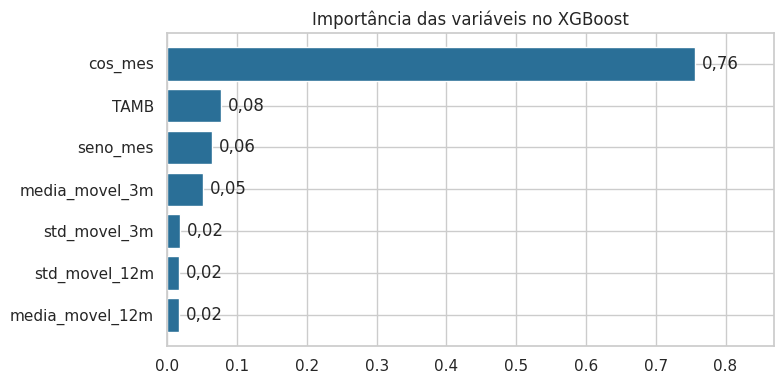

In [18]:
importancia = pd.Series(modelo.feature_importances_, index=x_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importancia.index, importancia.values, color="#2a6f97")
for i, v in enumerate(importancia.values):
    ax.text(v + 0.01, i, f"{v:.2f}".replace(".", ","), va="center")
ax.set_xlim(0, importancia.max() * 1.15)
ax.set_title("Importância das variáveis no XGBoost")
fig.tight_layout()
fig.savefig(IMG / "05_importancia_variaveis.png", dpi=150)
plt.show()

**Leitura:** o `cos_mes` concentra a maior parte da importância, o que confirma a leitura anterior: o modelo usa principalmente o mês do ano. As médias e desvios móveis contribuem pouco.

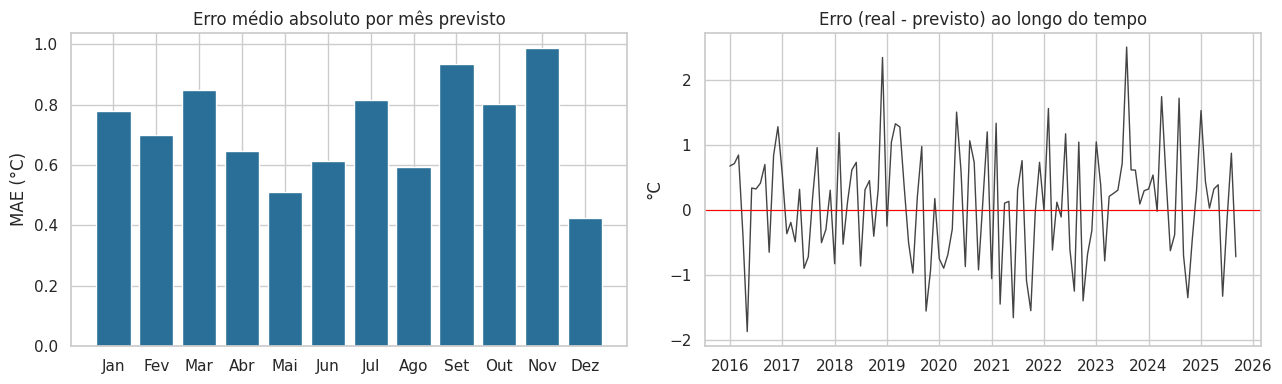

Erro médio (viés): 0.11 °C | maior erro absoluto: 2.51 °C


In [19]:
# Onde o modelo erra mais? Erro por mês e ao longo do tempo
analise = pd.DataFrame({"real": y_test["TARGET"], "previsto": pred_test["Y_PRED"]})
analise["erro"] = analise["real"] - analise["previsto"]
analise["mes_alvo"] = analise.index.month % 12 + 1

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
erro_mes = analise.groupby("mes_alvo")["erro"].apply(lambda s: s.abs().mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar([meses[m - 1] for m in erro_mes.index], erro_mes.values, color="#2a6f97")
axes[0].set_title("Erro médio absoluto por mês previsto")
axes[0].set_ylabel("MAE (°C)")

axes[1].plot(analise.index, analise["erro"], color="#444", linewidth=1)
axes[1].axhline(0, color="red", linewidth=0.8)
axes[1].set_title("Erro (real - previsto) ao longo do tempo")
axes[1].set_ylabel("°C")
fig.tight_layout()
fig.savefig(IMG / "06_erros_do_modelo.png", dpi=150)
plt.show()

print(f"Erro médio (viés): {analise['erro'].mean():.2f} °C | maior erro absoluto: {analise['erro'].abs().max():.2f} °C")

**Leitura:** o erro não é igual em todos os meses: alguns meses são mais difíceis de prever que outros. O viés médio é pequeno (o modelo não erra sistematicamente para cima ou para baixo), mas existem meses isolados com erros acima de 2 °C.

## 8. Validação cruzada temporal

In [20]:
# Em vez de um único corte treino/teste, repete a avaliação em 5 janelas sucessivas de 60 meses
tscv = TimeSeriesSplit(n_splits=5, test_size=60)
resultado_cv = []
for i, (idx_treino, idx_teste) in enumerate(tscv.split(x_features), start=1):
    m = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3,
                     colsample_bytree=0.8, subsample=0.8, reg_alpha=0.1, reg_lambda=0.1)
    m.fit(x_features.iloc[idx_treino], y_target.iloc[idx_treino])
    p = m.predict(x_features.iloc[idx_teste])
    resultado_cv.append({
        "Dobra": i,
        "Período de teste": f"{x_features.index[idx_teste[0]]:%m/%Y} a {x_features.index[idx_teste[-1]]:%m/%Y}",
        "R²": r2_score(y_target.iloc[idx_teste], p),
        "MAE (°C)": mean_absolute_error(y_target.iloc[idx_teste], p),
    })

cv = pd.DataFrame(resultado_cv).set_index("Dobra")
display(cv.round(2))
print(f"Média -> R²: {cv['R²'].mean():.2f} | MAE: {cv['MAE (°C)'].mean():.2f} °C")

,Período de teste,R²,MAE (°C)
Dobra,,,
1,10/2000 a 09/2005,0.74,0.81
2,10/2005 a 09/2010,0.85,0.67
3,10/2010 a 09/2015,0.83,0.73
4,10/2015 a 09/2020,0.87,0.69
5,10/2020 a 09/2025,0.82,0.76


Média -> R²: 0.82 | MAE: 0.73 °C


**Leitura:** o desempenho varia entre as janelas, mas fica sempre na mesma faixa (R² entre ~0,74 e ~0,87). A primeira janela, com menos dados de treino, é a mais fraca. O resultado do corte único de 2016 em diante não foi um acaso favorável.

## 9. Conclusões

1. O XGBoost prevê a temperatura do mês seguinte com **erro médio de cerca de 0,7 °C** e R² de ~0,85 no teste.
2. Isso é bem melhor que repetir o mês atual ou o mesmo mês do ano anterior, mas **equivale a usar a média histórica de cada mês** ou uma regressão linear simples. O modelo aprendeu quase só a sazonalidade.
3. Existe um sinal de sobreajuste (R² de ~0,96 no treino contra ~0,85 no teste), e a validação cruzada temporal mostra desempenho consistente entre janelas.
4. A conclusão prática: para este problema, uma média climatológica já resolve quase tudo. Modelos complexos só valem a pena se houver variáveis que tragam informação nova.

## 10. Limitações e próximos passos

**Limitações**
- As variáveis usam só a própria temperatura passada. Fatores como El Niño, umidade ou pressão não foram incluídos.
- O horizonte de previsão é de apenas 1 mês.
- Os hiperparâmetros foram fixados, sem busca por melhores valores.
- As diferenças de poucos centésimos entre modelos não são estatisticamente conclusivas.

**Próximos passos**
- Incluir variáveis externas (umidade, pressão, índices climáticos como o El Niño) e testar se vencem a climatologia.
- Testar outros horizontes (3 e 6 meses) e outros modelos (SARIMA, Prophet).
- Ajustar hiperparâmetros com validação cruzada temporal.
- Gerar a previsão dos próximos meses com intervalo de confiança.